# Предположения линейной регрессии: проверяем руками

Ноутбук к теме [`lesson.md`](lesson.md). Здесь мы не пытаемся формально доказать все теоремы, а смотрим, **какие последствия** имеют нарушения предположений: форма остатков, нестабильность коэффициентов, неверная неопределённость и смещение из-за эндогенности.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(0)
C_BG, C_INK, C_GRAY = "#faf9f5", "#141413", "#b0aea5"
C_ORANGE, C_BLUE, C_GREEN = "#d97757", "#6a9bcc", "#788c5d"
plt.rcParams.update({"figure.facecolor": C_BG, "axes.facecolor": C_BG,
                     "axes.edgecolor": C_GRAY, "text.color": C_INK,
                     "xtick.color": C_INK, "ytick.color": C_INK,
                     "font.size": 11, "legend.frameon": False})

def add_intercept(X):
    return np.column_stack([np.ones(len(X)), X])

def fit_ols(X, y):
    return np.linalg.lstsq(add_intercept(X), y, rcond=None)[0]

def predict(beta, X):
    return add_intercept(X) @ beta


## 1. Линейность среднего: остатки показывают форму ошибки

Сравним линейную зависимость с квадратичной. В обоих случаях OLS можно посчитать, но прямая для квадратичной зависимости оставляет систематический рисунок в остатках.

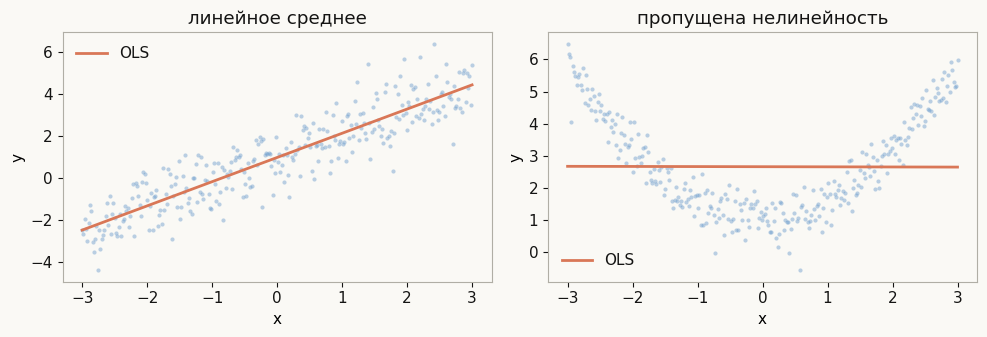

корреляция остатка с x^2: +0.957
систематическая корреляция с пропущенным базисом — сигнал расширить модель


In [2]:
x = np.linspace(-3, 3, 300)
y_linear = 1.0 + 1.2 * x + rng.normal(0, 0.9, len(x))
y_curve = 1.0 + 0.55 * x**2 + rng.normal(0, 0.45, len(x))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, y, title in zip(axes, (y_linear, y_curve), ("линейное среднее", "пропущена нелинейность")):
    b = fit_ols(x, y)
    fitted = predict(b, x)
    ax.scatter(x, y, s=9, color=C_BLUE, alpha=0.45, linewidths=0)
    ax.plot(x, fitted, color=C_ORANGE, lw=2, label="OLS")
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()
fig.tight_layout()
plt.show()

b = fit_ols(x, y_curve)
resid = y_curve - predict(b, x)
print(f"корреляция остатка с x^2: {np.corrcoef(resid, x**2)[0, 1]:+.3f}")
print("систематическая корреляция с пропущенным базисом — сигнал расширить модель")


## 2. Гомоскедастичность: коэффициент может остаться честным, SE — нет

Сделаем две выборки с одной и той же средней функцией, но с разным разбросом. Вторая имеет ошибку, растущую вместе с `x`. График остатков выглядит как конус. Без специализированных covariance-оценок стандартная ошибка OLS использует неправильную формулу.

In [3]:
x = rng.uniform(0, 10, 500)
for label, noise in (("постоянная дисперсия", np.full(len(x), 1.0)),
                     ("дисперсия растёт", 0.2 + 0.18 * x)):
    y = 2.0 + 0.8 * x + rng.normal(0, noise)
    b = fit_ols(x, y)
    resid = y - predict(b, x)
    print(f"{label:20s}: beta1={b[1]:.3f}, corr(|resid|, x)={np.corrcoef(np.abs(resid), x)[0,1]:+.3f}")


постоянная дисперсия: beta1=0.810, corr(|resid|, x)=-0.023
дисперсия растёт    : beta1=0.800, corr(|resid|, x)=+0.467


## 3. Мультиколлинеарность: вклад в сумму стабилен, отдельные коэффициенты — нет

Два признака почти дублируют друг друга. Повторим выборку много раз и посмотрим на оценки коэффициентов.

средние оценки: [2.03  1.972]
std отдельных коэффициентов: [0.396 0.398]
std суммы коэффициентов: 0.088


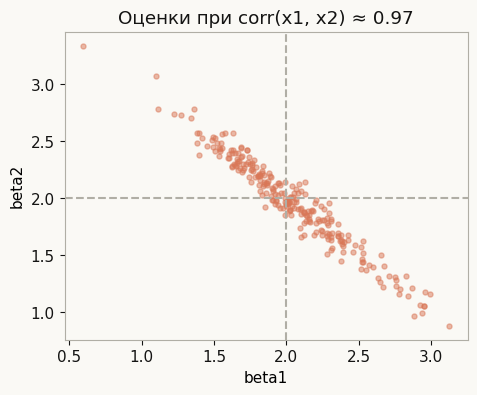

In [4]:
n, reps = 120, 250
est = []
for _ in range(reps):
    x1 = rng.normal(size=n)
    x2 = 0.97 * x1 + np.sqrt(1 - 0.97**2) * rng.normal(size=n)
    X = np.column_stack([x1, x2])
    y = 0.5 + X @ np.array([2.0, 2.0]) + rng.normal(0, 1.0, n)
    est.append(fit_ols(X, y)[1:])
est = np.array(est)

print("средние оценки:", est.mean(axis=0).round(3))
print("std отдельных коэффициентов:", est.std(axis=0).round(3))
print("std суммы коэффициентов:", est.sum(axis=1).std().round(3))

plt.figure(figsize=(5.2, 4))
plt.scatter(est[:, 0], est[:, 1], s=13, color=C_ORANGE, alpha=0.5)
plt.axvline(2, color=C_GRAY, ls="--"); plt.axhline(2, color=C_GRAY, ls="--")
plt.xlabel("beta1"); plt.ylabel("beta2")
plt.title("Оценки при corr(x1, x2) ≈ 0.97")
plt.show()


## 4. Эндогенность: больше данных не устраняет смещение

Создадим скрытую переменную `z`, которая влияет и на признак `x`, и на ошибку `u`. Истинный эффект `x` равен 2, но OLS видит также влияние `z` и получает устойчиво смещённый коэффициент.

истинный beta: 2.0
средняя OLS-оценка: 2.937
std OLS-оценки: 0.063


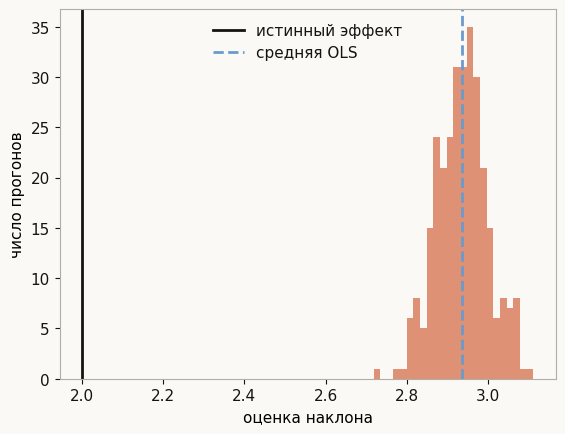

In [5]:
slopes = []
true_beta = 2.0
for _ in range(300):
    z = rng.normal(size=180)
    x = z + rng.normal(0, 0.7, len(z))
    u = 1.4 * z + rng.normal(0, 0.7, len(z))
    y = 1.0 + true_beta * x + u
    slopes.append(fit_ols(x, y)[1])
slopes = np.array(slopes)
print(f"истинный beta: {true_beta}")
print(f"средняя OLS-оценка: {slopes.mean():.3f}")
print(f"std OLS-оценки: {slopes.std():.3f}")
plt.hist(slopes, bins=24, color=C_ORANGE, alpha=0.8)
plt.axvline(true_beta, color=C_INK, lw=2, label="истинный эффект")
plt.axvline(slopes.mean(), color=C_BLUE, ls="--", lw=2, label="средняя OLS")
plt.xlabel("оценка наклона"); plt.ylabel("число прогонов"); plt.legend(); plt.show()


## 5. Разбиение по времени: независимость — это ещё и честная оценка

При временной зависимости нельзя случайно перемешивать соседние моменты. Покажем на AR(1)-ошибке, что соседние остатки похожи друг на друга.

In [6]:
n = 500
x = rng.normal(size=n)
eps = np.zeros(n)
for t in range(1, n):
    eps[t] = 0.85 * eps[t-1] + rng.normal()
y = 1 + 0.8 * x + eps
b = fit_ols(x, y)
resid = y - predict(b, x)
lag1 = np.corrcoef(resid[:-1], resid[1:])[0, 1]
print(f"оценка beta1: {b[1]:.3f}")
print(f"корреляция соседних остатков: {lag1:.3f}")
print("Для вывода нужны HAC/cluster SE или модель зависимости; для оценки прогноза — временной split.")


оценка beta1: 0.739
корреляция соседних остатков: 0.857
Для вывода нужны HAC/cluster SE или модель зависимости; для оценки прогноза — временной split.


## Что проверить после прогона

- Форма остатков против fitted values: дуга — нелинейность, конус — гетероскедастичность.
- Разброс коэффициентов по bootstrap-повторам: вытянутое облако — мультиколлинеарность.
- Средняя оценка при скрытой общей причине: устойчивое смещение — эндогенность.
- Корреляция соседних остатков и правила разбиения: случайный split может переоценивать качество.